# 2. Прогноз оттока абонентов: бейзлайн против градиентного бустинга

**Данные:** публичный датасет IBM Telco Customer Churn (7 043 абонента, 21 признак).
**Задача:** предсказать, кто уйдёт, и решить, кому из абонентов выгодно сделать предложение об удержании.

План: подготовка данных → бейзлайн (логистическая регрессия) → LightGBM → честная проверка на
отложенной выборке → интерпретация → экономика удержания.

In [1]:
import sys, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False})
GREEN, PURPLE, GREY = '#00B956', '#731982', '#9AA0A6'

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve
import lightgbm as lgb

df = pd.read_csv('../data/raw/Telco-Customer-Churn.csv')
df.shape

(7043, 21)

## Подготовка и первый взгляд

In [2]:
# TotalCharges читается как текст: у 11 новых абонентов (tenure = 0) там пробел
print('пустых TotalCharges:', (df.TotalCharges.str.strip() == '').sum())
df['TotalCharges'] = pd.to_numeric(df.TotalCharges, errors='coerce').fillna(0)
df['churn'] = (df.Churn == 'Yes').astype(int)
print(f"доля ушедших: {df.churn.mean():.1%}")
df.groupby('Contract').churn.agg(['mean', 'size']).rename(columns={'mean': 'доля оттока', 'size': 'абонентов'})

пустых TotalCharges: 11
доля ушедших: 26.5%


,доля оттока,абонентов
Contract,,
Month-to-month,0.427097,3875
One year,0.112695,1473
Two year,0.028319,1695


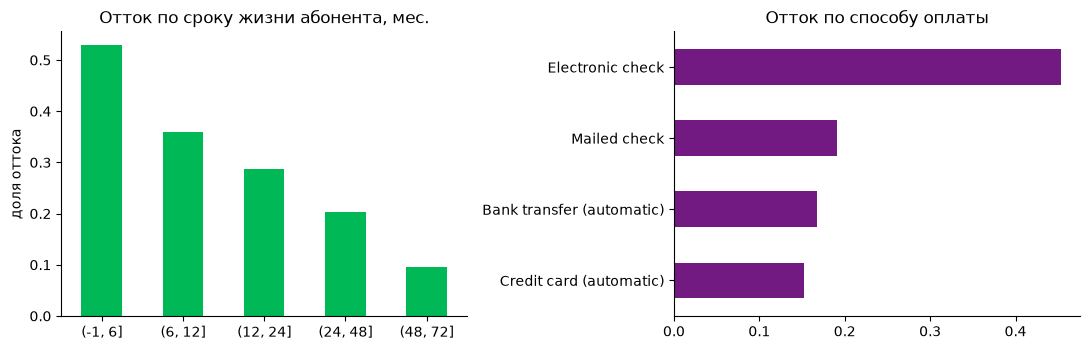

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
df.groupby(pd.cut(df.tenure, [-1, 6, 12, 24, 48, 72])).churn.mean().plot.bar(ax=ax[0], color=GREEN, rot=0)
ax[0].set(title='Отток по сроку жизни абонента, мес.', xlabel='', ylabel='доля оттока')
df.groupby('PaymentMethod').churn.mean().sort_values().plot.barh(ax=ax[1], color=PURPLE)
ax[1].set(title='Отток по способу оплаты', ylabel='')
plt.tight_layout(); plt.show()

Уходят в основном **новые** абоненты на **помесячном контракте**, платящие электронным чеком.
Добавлю пару признаков, которые отражают это явно, и разобью данные: 80% — обучение, 20% — отложенный тест,
который модель не видит до самого конца.

In [4]:
df['avg_charge'] = df.TotalCharges / df.tenure.replace(0, 1)
df['n_services'] = (df[['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
                        'StreamingTV', 'StreamingMovies']] == 'Yes').sum(axis=1)
num = ['tenure', 'MonthlyCharges', 'TotalCharges', 'avg_charge', 'n_services', 'SeniorCitizen']
cat = [c for c in df.columns if df[c].dtype == object and c not in ('customerID', 'Churn')]
X, y = df[num + cat], df.churn
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
cv = StratifiedKFold(5, shuffle=True, random_state=42)
len(X_tr), len(X_te)

(5634, 1409)

## Бейзлайн: логистическая регрессия

In [5]:
pre = ColumnTransformer([('num', StandardScaler(), num), ('cat', OneHotEncoder(handle_unknown='ignore'), cat)])
logreg = make_pipeline(pre, LogisticRegression(max_iter=2000, C=0.5))
cv_lr = cross_val_score(logreg, X_tr, y_tr, cv=cv, scoring='roc_auc')
print(f'LogReg  CV ROC-AUC: {cv_lr.mean():.3f} ± {cv_lr.std():.3f}')

LogReg  CV ROC-AUC: 0.820 ± 0.013


## LightGBM

In [6]:
X_tr_l, X_te_l = X_tr.copy(), X_te.copy()
for c in cat:
    X_tr_l[c] = X_tr_l[c].astype('category')
    X_te_l[c] = pd.Categorical(X_te_l[c], categories=X_tr_l[c].cat.categories)
# Неглубокие деревья и сильная регуляризация: данных всего ~5,6 тыс. строк
gbm = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.02, num_leaves=8, min_child_samples=40,
                         subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=5,
                         verbose=-1, random_state=42)
cv_gb = cross_val_score(gbm, X_tr_l, y_tr, cv=cv, scoring='roc_auc')
print(f'LightGBM CV ROC-AUC: {cv_gb.mean():.3f} ± {cv_gb.std():.3f}')

LightGBM CV ROC-AUC: 0.831 ± 0.013


## Проверка на отложенной выборке

In [7]:
logreg.fit(X_tr, y_tr); gbm.fit(X_tr_l, y_tr)
p_lr, p_gb = logreg.predict_proba(X_te)[:, 1], gbm.predict_proba(X_te_l)[:, 1]

def lift_at(y, p, q=0.2):
    k = int(len(y) * q); top = np.argsort(-p)[:k]
    return np.asarray(y)[top].mean() / np.mean(y)

res = pd.DataFrame({
    'ROC-AUC': [roc_auc_score(y_te, p) for p in (p_lr, p_gb)],
    'PR-AUC': [average_precision_score(y_te, p) for p in (p_lr, p_gb)],
    'Lift@20%': [lift_at(y_te, p) for p in (p_lr, p_gb)],
}, index=['Логистическая регрессия', 'LightGBM']).round(3)
res

,ROC-AUC,PR-AUC,Lift@20%
Логистическая регрессия,0.826,0.621,2.413
LightGBM,0.841,0.649,2.453


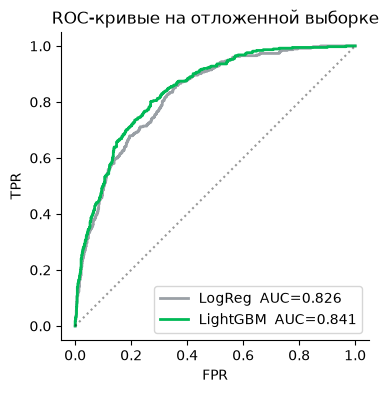

In [8]:
for p, name, col in [(p_lr, 'LogReg', GREY), (p_gb, 'LightGBM', GREEN)]:
    fpr, tpr, _ = roc_curve(y_te, p); plt.plot(fpr, tpr, label=f'{name}  AUC={roc_auc_score(y_te, p):.3f}', color=col, lw=2)
plt.plot([0, 1], [0, 1], ls=':', color='k', alpha=.4)
plt.gca().set(title='ROC-кривые на отложенной выборке', xlabel='FPR', ylabel='TPR', aspect='equal'); plt.legend(); plt.show()

**Вывод.** LightGBM лучше бейзлайна, но **ненамного**: +0,01 ROC-AUC на кросс-валидации и +0,015
на отложенной выборке, PR-AUC 0,65 против 0,62. Зависимости здесь в основном простые и монотонные
(срок жизни, тип контракта, цена), и линейная модель ловит большую их часть. Выбор между моделями —
это компромисс: бустинг даёт немного больше точности, логистическая регрессия проще объясняется
бизнесу. Ниже для экономики использую LightGBM.

## Что влияет на отток

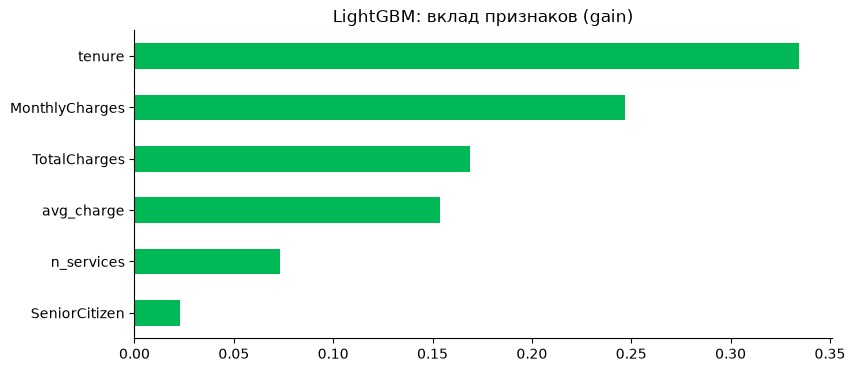

In [9]:
imp = pd.Series(gbm.booster_.feature_importance('gain'), index=X_tr_l.columns)
(imp / imp.sum()).sort_values().tail(10).plot.barh(color=GREEN)
plt.title('LightGBM: вклад признаков (gain)'); plt.show()

## Экономика: кому делать предложение об удержании

Допущения (их стоит согласовать с бизнесом):
* предложение стоит оператору **скидку в размере одного месячного платежа**;
* оно удерживает **30%** тех, кто действительно собирался уйти;
* удержанный абонент приносит ещё **12 месяцев** платы.

Сортируем абонентов по ожидаемой выгоде (вероятность × ценность) и ищем, скольким выгодно звонить.

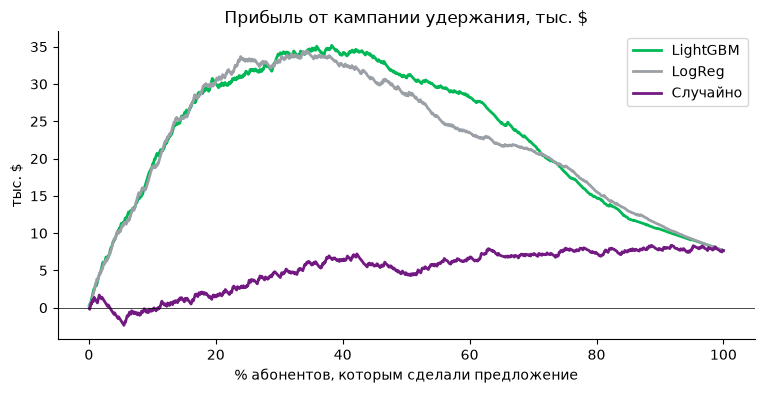

Оптимум: предложение 38% абонентов с наибольшим риском × платежом, прибыль 35,184 $ на 1409 абонентов тестовой выборки
LightGBM  максимум    35,184 $   при охвате 38%:    35,184 $   всем:     7,672 $
LogReg    максимум    34,401 $   при охвате 38%:    33,495 $   всем:     7,672 $
Случайно  максимум     8,376 $   при охвате 38%:     6,532 $   всем:     7,672 $


In [10]:
mc = X_te.MonthlyCharges.to_numpy(); yt = y_te.to_numpy()
def profit_curve(p, save_rate=0.30, months=12):
    order = np.argsort(-(p * mc))
    gain = yt[order] * save_rate * mc[order] * months - mc[order]
    return np.cumsum(gain)
curves = {'LightGBM': profit_curve(p_gb), 'LogReg': profit_curve(p_lr),
          'Случайно': profit_curve(np.random.default_rng(0).random(len(yt)))}
share = np.arange(1, len(yt) + 1) / len(yt)
for (n, c), col in zip(curves.items(), [GREEN, GREY, PURPLE]):
    plt.plot(share * 100, c / 1e3, label=n, color=col, lw=2)
plt.axhline(0, color='k', lw=.5)
plt.gca().set(title='Прибыль от кампании удержания, тыс. $', xlabel='% абонентов, которым сделали предложение', ylabel='тыс. $')
plt.legend(); plt.show()
best = curves['LightGBM'].argmax()
print(f'Оптимум: предложение {share[best]:.0%} абонентов с наибольшим риском × платежом, '
      f'прибыль {curves["LightGBM"][best]:,.0f} $ на {len(yt)} абонентов тестовой выборки')
for n, c in curves.items():
    print(f'{n:9s} максимум {c.max():>9,.0f} $   при охвате 38%: {c[best]:>9,.0f} $   всем: {c[-1]:>9,.0f} $')

**Итог.** Если сделать предложение 38% абонентов, отобранных моделью, кампания приносит **~35 тыс. $**.
Это в **4,6 раза** больше, чем предложение всем подряд (~7,7 тыс. $), и при этом скидок раздаётся меньше.
Предложение выгодно делать не всем, а только верхней части списка по ожидаемой потере. Как и в моём
проекте на хакатоне, сортировать стоит по **деньгам** (риск × платёж), а не по одной вероятности.

**Ограничения:** датасет статичный (один срез без истории по месяцам), поэтому настоящую проверку по
времени здесь сделать нельзя. Как выглядела бы витрина с историей, показано в `sql/02_mart.sql`.